<a href="https://colab.research.google.com/github/trialdyk/PBL-Skin-Problem-Detector/blob/main/machine-learning/Marsya/Train_Marsya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 108.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 4.5 MB/s eta 0:00:00


In [ ]:
from roboflow import Roboflow

rf = Roboflow(api_key="y8gLRKWv4JW5mXZr1Mn0")
project = rf.workspace("taschenbier").project("acne-severity-classification")
version = project.version(3)
dataset = version.download("folder")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Acne-Severity-Classification-3 in folder:: 100%|██████████| 6471/6471 [00:01<00:00, 3883.00it/s]


In [ ]:
import os

DATASET_PATH = dataset.location
print(f"Lokasi dataset: {DATASET_PATH}")

# Cek distribusi gambar pada folder train, valid, dan test
for split in ['train', 'valid', 'test']:
    split_dir = os.path.join(DATASET_PATH, split)
    if os.path.exists(split_dir):
        print(f"\n=== Folder {split.upper()} ===")
        total = 0
        for cls in sorted(os.listdir(split_dir)):
            cls_path = os.path.join(split_dir, cls)
            if os.path.isdir(cls_path):
                count = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
                total += count
                print(f"  - Kelas '{cls}': {count} foto")
        print(f"  Total {split}: {total} foto")

Lokasi dataset: /content/Acne-Severity-Classification-3

=== Folder TRAIN ===
  - Kelas 'IGA0': 1113 foto
  - Kelas 'IGA1': 1257 foto
  - Kelas 'IGA2': 2730 foto
  - Kelas 'IGA3': 501 foto
  - Kelas 'IGA4': 390 foto
  Total train: 5991 foto

=== Folder VALID ===
  - Kelas 'IGA0': 78 foto
  - Kelas 'IGA1': 48 foto
  - Kelas 'IGA2': 136 foto
  - Kelas 'IGA3': 34 foto
  - Kelas 'IGA4': 29 foto
  Total valid: 325 foto

=== Folder TEST ===
  - Kelas 'IGA0': 30 foto
  - Kelas 'IGA1': 20 foto
  - Kelas 'IGA2': 58 foto
  - Kelas 'IGA3': 16 foto
  - Kelas 'IGA4': 11 foto
  Total test: 135 foto


## Memuat Data dan Praproses Gambar (224 x 224 Piksel)

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dir = os.path.join(DATASET_PATH, 'train')
valid_dir = os.path.join(DATASET_PATH, 'valid')
test_dir  = os.path.join(DATASET_PATH, 'test')

# Memuat dataset dari masing-masing subset
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    shuffle=False, # Jangan diacak agar urutan sesuai saat dievaluasi di Confusion Matrix
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("\nNama Kelas:", class_names)
print("Jumlah Kelas:", NUM_CLASSES)

# Augmentasi ringan khusus untuk data latih
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomBrightness(factor=0.05)
], name="augmentasi_ringan")

# Optimasi kecepatan pembacaan data ke GPU
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
valid_ds = valid_ds.prefetch(buffer_size=AUTOTUNE)
test_ds  = test_ds.prefetch(buffer_size=AUTOTUNE)

Found 5991 files belonging to 5 classes.
Found 325 files belonging to 5 classes.
Found 135 files belonging to 5 classes.

Nama Kelas: ['IGA0', 'IGA1', 'IGA2', 'IGA3', 'IGA4']
Jumlah Kelas: 5


## Membangun Model dengan Pretraining

In [ ]:
# 1. Muat Pretrained Model MobileNetV2 (bobot ImageNet) tanpa layer paling atas (include_top=False)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet' # <--- Menggunakan Pretraining ImageNet
)

# 2. Bekukan (freeze) bobot dasar MobileNetV2 untuk pelatihan awal (Baseline)
base_model.trainable = False

# 3. Rangkai arsitektur model
inputs = tf.keras.Input(shape=(224, 224, 3), name="input_wajah")
x = data_augmentation(inputs)

# Normalisasi piksel sesuai standar MobileNetV2 (mengubah rentang [0, 255] ke [-1, 1])
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# Lewatkan ke base_model MobileNetV2
x = base_model(x, training=False)

# Tambahkan Classification Head (Lapisan Klasifikasi Baru)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
x = tf.keras.layers.Dense(128, activation='relu')(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax', name="output_keparahan")(x)

model = tf.keras.Model(inputs, outputs, name="DermaScan_Pretrained_MobileNetV2")

# 4. Compile model untuk Tahap 1
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DermaScan_Pretrained_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_wajah (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentasi_ringan (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_keparahan (Dense)        │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Pelatihan Tahao 1 (Baseline Training - Melatih Lapisan Klasifikasi)

In [ ]:
EPOCHS_STAGE_1 = 10

callbacks_stage_1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        'dermascan_baseline_best.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

print("=== Memulai Training Tahap 1 (Feature Extraction / Baseline) ===")
history_1 = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS_STAGE_1,
    callbacks=callbacks_stage_1
)

=== Memulai Training Tahap 1 (Feature Extraction / Baseline) ===
Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.4354 - loss: 1.2903
Epoch 1: val_loss improved from None to 0.84743, saving model to dermascan_baseline_best.keras

Epoch 1: finished saving model to dermascan_baseline_best.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 156ms/step - accuracy: 0.4809 - loss: 1.1058 - val_accuracy: 0.5662 - val_loss: 0.8474
Epoch 2/10
187/188 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.5538 - loss: 0.9034
Epoch 2: val_loss improved from 0.84743 to 0.77065, saving model to dermascan_baseline_best.keras

Epoch 2: finished saving model to dermascan_baseline_best.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 79ms/step - accuracy: 0.5623 - loss: 0.8794 - val_accuracy: 0.6062 - val_loss: 0.7707
Epoch 3/10
187/188 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.5917 - loss: 0.8427
Epoch 3: val_loss improved from 0.77065 to 0.71055, saving model to dermascan_baseline_best.keras

Epoch 3: fin

## Pelatihan Tahap 2 (Fine Tuning - Penyempurnaan Model)

In [ ]:
# 1. Buka kunci (unfreeze) base_model
base_model.trainable = True

# Hanya buka 30 layer paling akhir, bekukan sisanya
fine_tune_at = len(base_model.layers) - 30
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Biarkan layer BatchNormalization tetap beku agar statistik pretraining tidak rusak
for layer in base_model.layers[fine_tune_at:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# 2. Compile ulang dengan learning rate kecil (1e-5)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

EPOCHS_STAGE_2 = 10
total_epochs = len(history_1.epoch) + EPOCHS_STAGE_2

callbacks_stage_2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        'dermascan_finetuned_best.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

print("=== Memulai Training Tahap 2 (Fine-Tuning) ===")
history_2 = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=total_epochs,
    initial_epoch=len(history_1.epoch),
    callbacks=callbacks_stage_2
)

=== Memulai Training Tahap 2 (Fine-Tuning) ===
Epoch 8/17
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.6226 - loss: 0.7672
Epoch 8: val_loss improved from None to 0.67698, saving model to dermascan_finetuned_best.keras

Epoch 8: finished saving model to dermascan_finetuned_best.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 39s 139ms/step - accuracy: 0.6343 - loss: 0.7521 - val_accuracy: 0.6769 - val_loss: 0.6770
Epoch 9/17
187/188 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.6311 - loss: 0.7308
Epoch 9: val_loss improved from 0.67698 to 0.65722, saving model to dermascan_finetuned_best.keras

Epoch 9: finished saving model to dermascan_finetuned_best.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 77ms/step - accuracy: 0.6470 - loss: 0.7167 - val_accuracy: 0.7262 - val_loss: 0.6572
Epoch 10/17
187/188 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.6446 - loss: 0.7097
Epoch 10: val_loss improved from 0.65722 to 0.62870, saving model to dermascan_finetuned_best.keras

Epoch 10: finished savi

## Visualisasi Grafik dan Evaluasi pada Data Uji

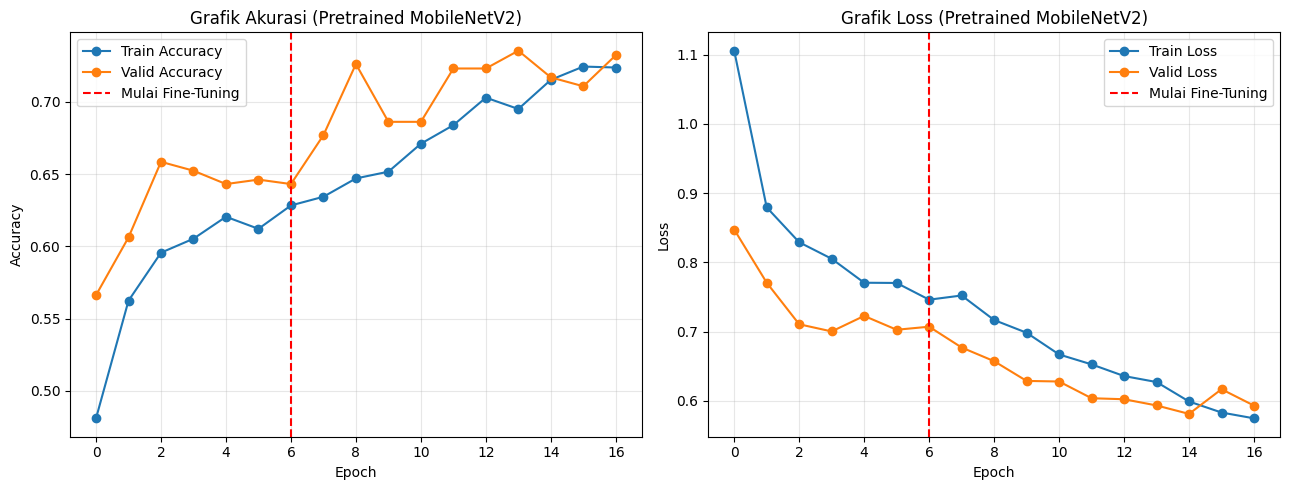


=== HASIL EVALUASI MODEL PADA DATA UJI (TEST SET) ===
              precision    recall  f1-score   support

        IGA0     0.7576    0.8333    0.7937        30
        IGA1     0.6800    0.8500    0.7556        20
        IGA2     0.7321    0.7069    0.7193        58
        IGA3     0.7500    0.3750    0.5000        16
        IGA4     0.7692    0.9091    0.8333        11

    accuracy                         0.7333       135
   macro avg     0.7378    0.7349    0.7204       135
weighted avg     0.7352    0.7333    0.7245       135



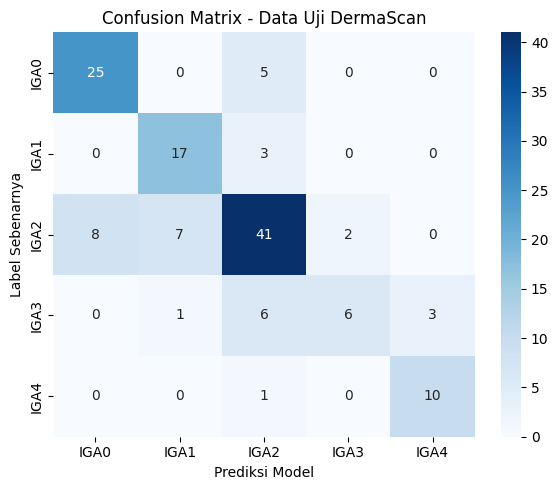

In [ ]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Plot Grafik Accuracy & Loss (Tahap 1 + Tahap 2)
acc = history_1.history['accuracy'] + history_2.history['accuracy']
val_acc = history_1.history['val_accuracy'] + history_2.history['val_accuracy']
loss = history_1.history['loss'] + history_2.history['loss']
val_loss = history_1.history['val_loss'] + history_2.history['val_loss']

batas_finetune = len(history_1.epoch) - 1

plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Train Accuracy', marker='o')
plt.plot(val_acc, label='Valid Accuracy', marker='o')
plt.axvline(x=batas_finetune, color='red', linestyle='--', label='Mulai Fine-Tuning')
plt.title('Grafik Akurasi (Pretrained MobileNetV2)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(loss, label='Train Loss', marker='o')
plt.plot(val_loss, label='Valid Loss', marker='o')
plt.axvline(x=batas_finetune, color='red', linestyle='--', label='Mulai Fine-Tuning')
plt.title('Grafik Loss (Pretrained MobileNetV2)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Evaluasi pada Data Uji (Test Set)
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels.numpy(), axis=1))

print("\n=== HASIL EVALUASI MODEL PADA DATA UJI (TEST SET) ===")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# 3. Visualisasi Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Data Uji DermaScan')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()